<center>
<img src="https://drive.google.com/uc?id=1cwPX7BgVIwtG7Rpd9FQGdfOxaVrgaR59" alt="Descripción" width="178">

<img src="https://drive.google.com/uc?id=1bLJqVtTvaYSS46sJ_VSVmY7j8QgfhAln" alt="Descripción" width="100">
</center>

---
# **Bioinformática 2026**

---
# Integrantes:
- ## Francisco Jose Rizzi, `LU= 766/23`
- ## Nicolas Wald, `LU= 780/23`
- ## Victor Orsingher, `LU= 668/20`

---

## Trabajo Final: La paradoja de la Hemoglobina E: análisis estructural-mecanístico in silico de la variante β-globina más prevalente del Sudeste Asiático

Una mirada bioinformática-estructural al panorama evolutivo de Deng et al. (2025)

---

# 0 - Instalacion de entorno y Funciones

Ejecutar esta celda antes de avanzar.

## Instalacion de subprocesos y dependencias :

In [ ]:
import subprocess
import sys

def run(cmd):
    print(f"→ {' '.join(cmd)}")
    subprocess.run(cmd, check=True)

# Actualizar repositorios
run(["apt-get", "update", "-qq"])

# Paquetes del sistema
run(["apt-get", "install", "-y", "-qq", "clustalw"])
run(["apt-get", "install", "-y", "-qq", "mafft"])
run(["apt-get", "install", "-y", "-qq", "hmmer"])

# Paquetes de Python
run([
    sys.executable, "-m", "pip", "install",
    "--quiet",
    "biopython",
    "seaborn",
    "pyhmmer",
    "pymsaviz"
])

print("\n✓ Todas las dependencias fueron instaladas correctamente.")

→ apt-get update -qq
→ apt-get install -y -qq clustalw
→ apt-get install -y -qq mafft
→ apt-get install -y -qq hmmer
→ /usr/bin/python3 -m pip install --quiet biopython seaborn pyhmmer pymsaviz

✓ Todas las dependencias fueron instaladas correctamente.


## Importado de Librerias:

In [ ]:
import pandas as pd
import numpy as np

import pyhmmer

from pymsaviz import MsaViz

from Bio import SeqIO, AlignIO, Entrez
from Bio.Seq import Seq
from Bio.SeqRecord import SeqRecord
from Bio.Phylo.TreeConstruction import DistanceCalculator, DistanceTreeConstructor
from Bio import Phylo
from Bio.PDB import PDBParser, Superimposer
from Bio.PDB.SASA import ShrakeRupley


import seaborn.objects as so
import seaborn as sns

print("✓ Imports OK")

✓ Imports OK


## Funciones utilizadas a lo largo del trabajo:

### Fase 3.2:

In [ ]:
# Filtra del Fasta las secuencias que sean Beta y estables.

def Filtrar_HemoBetas( ruta, salida ):
  with open(salida, "w") as out:
      for record in SeqIO.parse(ruta, "fasta"):
          titulo = record.description.upper()

          # Si el titulo tiene la palabra "Beta" y no tiene "LOW" ni "PREDICTED"

          if "BETA" in titulo and not any(x in titulo for x in ["LOW", "PREDICTED"]):
              SeqIO.write(record, out, "fasta")

In [ ]:
def CMD( comando ):
    subprocess.run(comando, check=True)

In [ ]:
def dmin(res_atoms, ref_atoms):
    """Distancia mínima (en Å) entre dos conjuntos de átomos."""
    return min(np.linalg.norm(a.coord - b.coord) for a in res_atoms for b in ref_atoms)

# 1- Introducción y pregunta biológica

La β-talasemia es la enfermedad monogénica más prevalente del Sudeste Asiático. Deng et al. (2025) reconstruyeron el origen evolutivo y la estructura haplotípica de sus mutaciones en el sur de China e identificaron trece variantes que explican aproximadamente el 95% de los casos. La mayoría de esas variantes actúan sobre la expresión del gen —por corrimiento del marco de lectura, terminación prematura, defectos de splicing o mutaciones de promotor— y solo dos son sustituciones missense. De estas, la Hemoglobina E [β26(B8) Glu→Lys; HBB:c.79G>A] es la relevante para este trabajo por su altísima frecuencia y su doble carácter.

La Hemoglobina E es doblemente peculiar: es a la vez una hemoglobina anómala y un alelo β⁺-talasémico, porque la sustitución en el codón 26 activa un sitio críptico de splicing en el exón 1 (Orkin et al., 1982), y participa en cerca del 50% de la talasemia severa a nivel mundial. Sin embargo, el abordaje de Deng et al., de naturaleza poblacional y evolutiva, no analiza el mecanismo a nivel de la proteína.

Pregunta biológica: ¿por qué una mutación de tan alto impacto clínico y tan alta frecuencia es, en términos estructurales, casi benigna?

# 2- Hipótesis de trabajo y resultados esperados

Dado que β26 ocupa la posición superficial B8, expuesta al solvente y ajena tanto a la coordinación del hemo como a la interfaz alostérica α1β2, y dado que el fenotipo de la Hemoglobina E deriva principalmente del defecto de splicing y no de una alteración estructural severa, nuestra hipótesis es que, al mapear las variantes del panel sobre la estructura tridimensional de la hemoglobina y analizar la conservación evolutiva de sus posiciones, encontraremos que la Hemoglobina E ocupa una posición estructuralmente permisiva —de alta accesibilidad al solvente y perturbación local mínima—, en contraste con las hemoglobinas inestables severas, que mapean a posiciones enterradas, de contacto con el hemo o de interfaz.

Es decir, la levedad estructural de β26 es lo que hace compatible con la función a una mutación cuyo daño real reside en la capa del ARN, condición que habría permitido su alta frecuencia bajo selección por malaria.

Resultados esperados: (i) una clasificación mecanística del panel, separando las variantes de expresión de las variantes estructurales; (ii) el mapa estructural tridimensional y el perfil de conservación de la posición de la Hemoglobina E; (iii) la comparación entre la forma silvestre y la mutante en términos de perturbación local; (iv) el contraste con variantes estructurales severas.

# 3 - Diseño experimental y metodología

## 3.1 - Datos


Trabajamos con la secuencia de la β-globina humana (UniProt P68871) y con estructuras experimentales de hemoglobina obtenidas del Protein Data Bank. Utilizamos la hemoglobina humana desoxigenada 2HHB, que representa el estado T, y la oxigenada 1HHO, que representa el estado R, como referencias de la forma silvestre en sus dos conformaciones alostéricas. Como estructura experimental de la variante empleamos 3DUT, cuya entrada en el PDB corresponde a la hemoglobina E desoxigenada (Glu26Lys) resuelta a pH fisiológico; verificamos que se trata del tetrámero α₂β₂ completo con sus grupos hemo y que porta efectivamente la sustitución en la cadena β, de modo que cualquier comparación con la forma silvestre pueda realizarse sobre el mismo estado conformacional (T) y no quede confundida con la transición alostérica T↔R.

Para el panel de variantes utilizamos los datos suplementarios de Deng et al. (2025) y, como catálogo de referencia de variantes estructurales de hemoglobina, la base HbVar.

## 3.2 - Triage mecanístico y búsqueda de ortólogos

### 3.2.1 - Clasificación mecanística del panel

Antes de cualquier análisis estructural separamos los mecanismos moleculares del panel de Deng et al. Para ello cargamos los datos suplementarios del trabajo y clasificamos las trece variantes por su consecuencia molecular.

> Es necesario tener cargado en el entorno el archivo `SupplementaryData1.xlsx` (datos suplementarios de Deng et al., 2025).

In [ ]:
ruta_archivo = "SupplementaryData1.xlsx"
df_raw = pd.read_excel(ruta_archivo, skiprows=1)

df_panel = df_raw.dropna(subset=["Common name"])[["Common name", "HGVS name", "Molecular consequence"]].copy()
df_panel.columns = ["Mutación", "HGVS", "Molecular consequence"]

print(f"Total de variantes en el panel: {len(df_panel)}")

df_panel

Total de variantes en el panel: 13


,Mutación,HGVS,Molecular consequence
1,CD41/42,HBB:c.126_129del,Frameshift
8,CD17,HBB:c.52A>T,Nonsense
15,IVS-II-654,HBB:c.316-197C>T,Splicing
23,-28,HBB:c.-78A>G,Promoter
28,HbE,HBB:c.79G>A,Missense
36,-50,HBB:c.-100G>A,Promoter
40,Hb NewYork,HBB:c.341T>A,Missense
44,CD71/72,HBB:c.217dupA,Frameshift
45,IVS-I-1,HBB:c.92+1G>T,Splicing
47,CD43,HBB:c.130G>T,Nonsense


De las trece variantes del panel, once actúan a nivel de la expresión del gen: tres por corrimiento del marco de lectura (frameshift), dos por codón de terminación prematura (nonsense), tres por defectos de splicing y tres por mutaciones de promotor. Ninguna de ellas produce un producto proteico completo con una sustitución puntual analizable a nivel estructural. Solo dos variantes son missense: la Hemoglobina E (HBB:c.79G>A) y la Hemoglobina New York (HBB:c.341T>A). De estas, restringimos el análisis estructural a la Hemoglobina E, por ser la variante de alta frecuencia poblacional y la que combina el carácter de hemoglobinopatía con el de alelo β⁺-talasémico.

### 3.2.2 - Busqueda de ortologos de globina en distintos vertebrados

Para situar la posición 26 en su contexto evolutivo realizamos una búsqueda de ortólogos de la β-globina con PSI-BLAST, partiendo de la secuencia humana P68871.

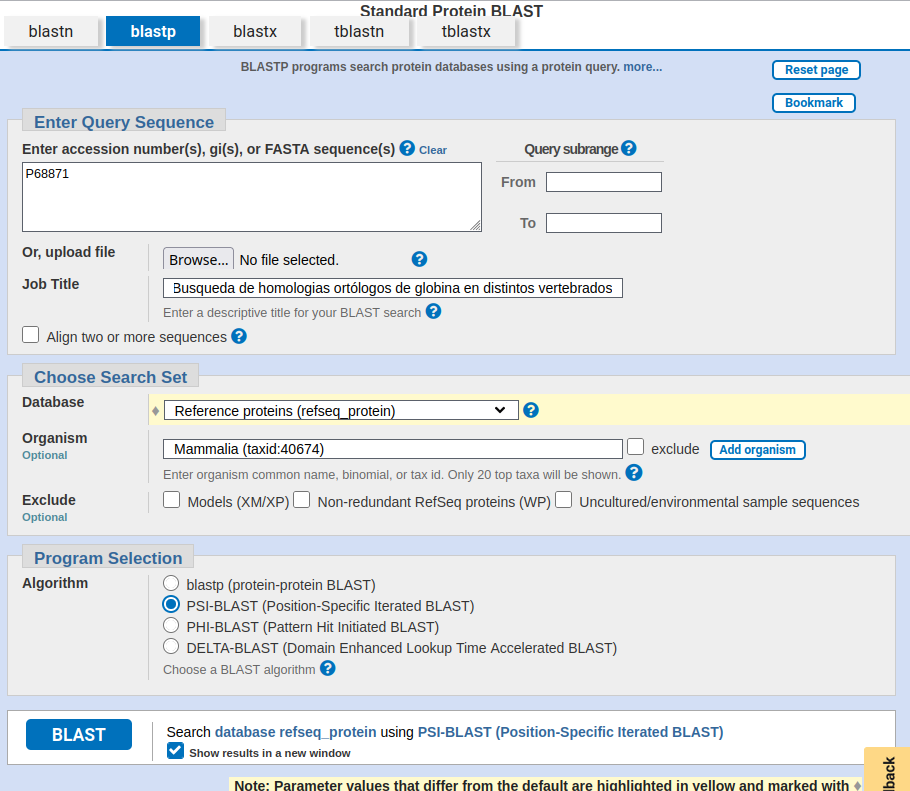

El criterio de búsqueda fue recuperar ortólogos de β-globina de mamíferos sobre RefSeq, evitando la redundancia y descartando estructuras de baja calidad o predichas. Restringimos la búsqueda exclusivamente a β-globinas, excluyendo las cadenas α, γ y ε e incluso las beta-like, con el fin de maximizar la relevancia del análisis de conservación específico de la cadena β. Optamos por esta estrategia en lugar de emplear directamente la familia beta-globina de InterPro/Pfam, dado que esta última incluye secuencias funcionalmente muy alejadas —como neuroglobinas u ortólogos de organismos no mamíferos— que diluirían la señal de conservación.

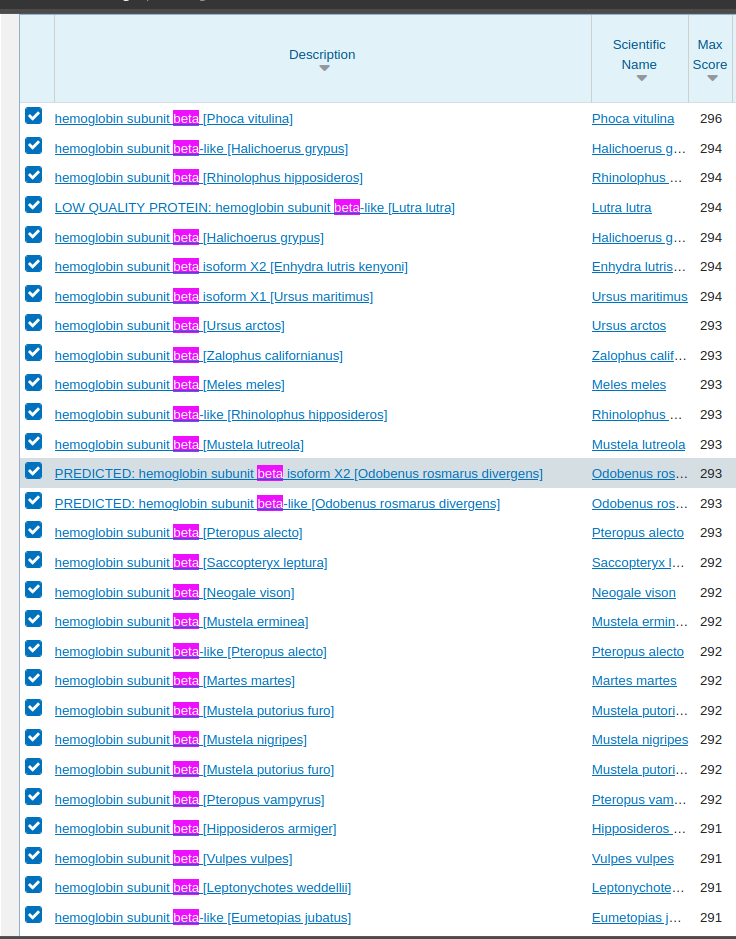

Iteramos PSI-BLAST hasta la quinta ronda de a 500 secuencias, punto en el que el conjunto recuperado resultó suficientemente homogéneo. A partir de ese resultado filtramos las secuencias para conservar únicamente las β-globinas de mamíferos y descartar las entradas de baja calidad, y las alineamos con MAFFT.

### 3.2.3: Limpieza de los ortologos y alineamiento.

Vamos a usar los resultados del PSI-Blast para quedarnos solo las HemoBetas de mamiferos y alinearlas para estudiar la conservacion evolutiva de la posicion de la mutacion.

> Es necesario tener cargado en el entorno el archivo `ResultadoPSiBLAST - HemoBeta - Mamiferos.fasta` (resultado de PSI-BLAST).

In [ ]:
# Limpiando los archivos
ruta = "ResultadoPSiBLAST - HemoBeta - Mamiferos.fasta"
Filtrar_HemoBetas(ruta, "HemoBetaSeqs.fasta")

Con las secuencias limpias ahora las alineamos.

In [ ]:
# Las alineamos
!mafft --maxiterate 1000 --localpair HemoBetaSeqs.fasta > HemoBeta_MSA.fasta

outputhat23=16
treein = 0
compacttree = 0
stacksize: 8192 kb
rescale = 1
All-to-all alignment.
tbfast-pair (aa) Version 7.490
alg=L, model=BLOSUM62, 2.00, -0.10, +0.10, noshift, amax=0.0
0 thread(s)

outputhat23=16
Loading 'hat3.seed' ... 
done.
Writing hat3 for iterative refinement
rescale = 1
Gap Penalty = -1.53, +0.00, +0.00
tbutree = 1, compacttree = 0
Constructing a UPGMA tree ... 
  220 / 227
done.

Progressive alignment ... 
STEP   226 /226 
done.
tbfast (aa) Version 7.490
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
1 thread(s)

minimumweight = 0.000010
autosubalignment = 0.000000
nthread = 0
randomseed = 0
blosum 62 / kimura 200
poffset = 0
niter = 16
sueff_global = 0.100000
nadd = 16
Loading 'hat3' ... done.
rescale = 1

  220 / 227
Segment   1/  1    1- 175
STEP 002-225-1  identical.   
Converged.

done
dvtditr (aa) Version 7.490
alg=A, model=BLOSUM62, 1.53, -0.00, -0.00, noshift, amax=0.0
0 thread(s)


Strategy:
 L-INS-i (Probably most accurate, very slow)
 

## 3.3 - Conservacion

Visualizamos el alineamiento múltiple resaltando la columna donde surge la mutación E→K. Debemos tener en cuenta que las secuencias del alineamiento incluyen la metionina inicial, que desplaza la numeración una posición: el residuo 26 de la proteína madura se corresponde con la columna 27 del alineamiento, de modo que marcamos esa columna.

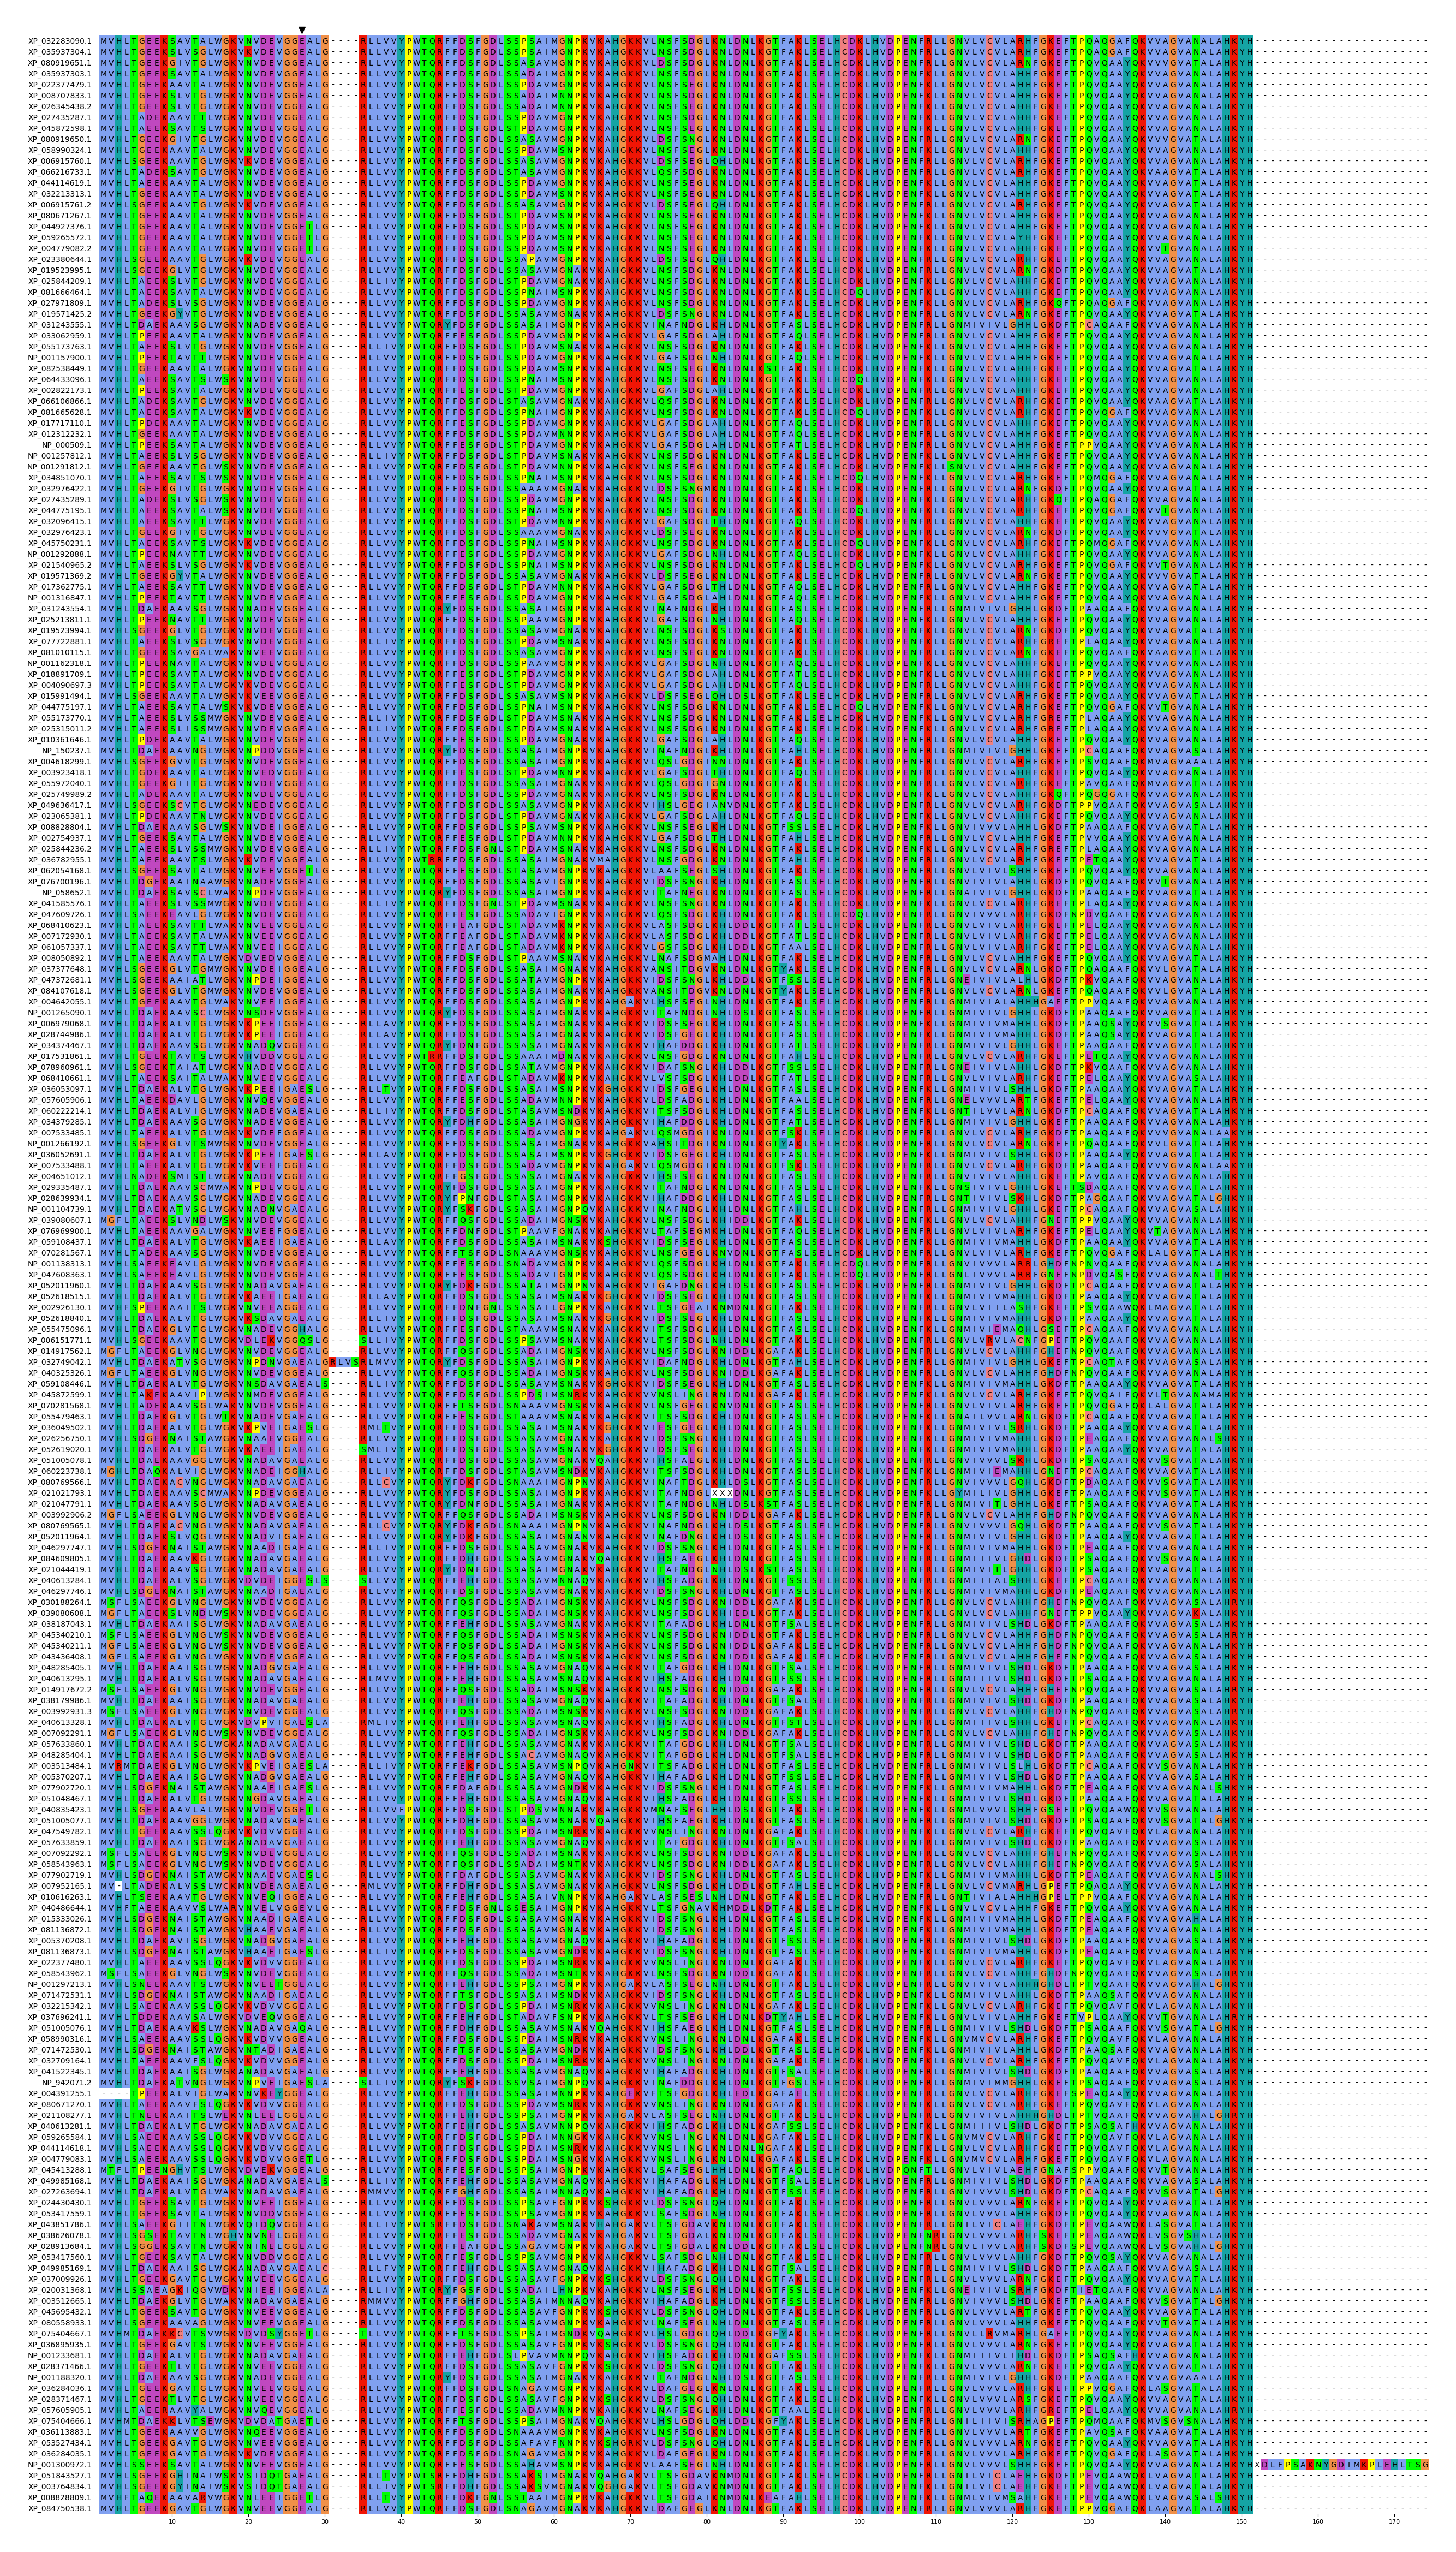

In [ ]:
mv = MsaViz(
    "HemoBeta_MSA.fasta",
    color_scheme="Clustal",
    wrap_length=200
)

mv.add_markers(
    positions=[27],
    marker="v",
    color="black",
    size=8
)

fig = mv.plotfig()

Para cuantificar la conservación medimos qué aminoácido ocupa la posición β26 en cada ortólogo. Todas las β-globinas que pasan el filtro tienen 147 residuos (la metionina inicial más los 146 de la cadena madura), sin inserciones ni deleciones en el extremo N, de manera que el índice 26 cae exactamente sobre β26. Contamos, por lo tanto, directamente sobre las secuencias filtradas, evitando la distorsión que introducen los gaps del alineamiento.

In [ ]:
secuencias = list(SeqIO.parse("HemoBetaSeqs.fasta", "fasta"))

longitudes = set(len(r.seq) for r in secuencias)
print("Longitudes presentes:", longitudes)

residuo_b26 = pd.Series([str(r.seq)[26] for r in secuencias])
print()
print((residuo_b26.value_counts() / residuo_b26.size * 100).round(1))

Longitudes presentes: {170, 143, 146, 147, 151}

E    97.4
H     0.9
Q     0.9
A     0.4
R     0.4
Name: count, dtype: float64


La posición β26 está ocupada por un ácido glutámico (E) en el 100% de las β-globinas de mamíferos recuperadas. No aparece ninguna lisina, ni ningún otro residuo, en esa posición: se trata de una posición esencialmente invariante.

Cabe una aclaración metodológica. Si en lugar de contar sobre las secuencias se lee directamente la columna 27 del alineamiento múltiple, el resultado es 98% de glutámico con un 1% de histidina y un 1% de glutamina. Esas dos apariciones no corresponden a residuos reales en la posición homóloga: son un artefacto de alineamiento, producto de que MAFFT introdujo un gap en el extremo N de dos secuencias y desplazó, para ellas, la lectura de la columna 27 hacia un residuo vecino. La medición sobre las secuencias sin gaps, que aquí adoptamos, muestra que la posición es glutámico en el 100% de los casos.

Esta conservación absoluta es significativa. La posición β26 no tolera sustituciones a lo largo de los mamíferos y la lisina de la Hemoglobina E no aparece de forma natural en ninguna especie: es, a nivel de secuencia, una sustitución evolutivamente inusual. Como veremos a continuación, esta fuerte conservación coexiste con una permisividad estructural notable, y esa aparente contradicción es central para el argumento del trabajo.

## 3.4 - Mapeo Estructural del residuo

En esta sección estudiamos la estructura tridimensional de la β-globina para determinar el contexto estructural de β26 y contrastarlo con posiciones de severidad conocida.

Sobre la numeración: las estructuras cristalográficas (2HHB, 1HHO, 3DUT) utilizan la numeración de la proteína madura, sin la metionina inicial; en ellas β26 corresponde al residuo 26 de la cadena β. Los modelos de AlphaFold, en cambio, se construyen a partir de la secuencia completa con la metionina inicial, por lo que en ellos la mutación E26K corresponde al residuo 27. Tenemos en cuenta este desplazamiento en cada análisis.

### 3.4.1 - Mapeo cuantitativo sobre la estructura desoxi (estado T)

Ubicamos β26 y un conjunto de posiciones de contraste sobre la estructura cristalográfica de la hemoglobina humana desoxigenada (2HHB) y clasificamos cada posición por su contexto estructural de forma cuantitativa, midiendo para cada residuo la distancia mínima al hierro del hemo más cercano y a las dos interfaces de la molécula: la de empaquetamiento α1β1 y la alostérica α1β2. La identidad del aminoácido no modifica la ubicación de la posición, de manera que la estructura silvestre es suficiente para clasificar el contexto.

In [ ]:
# Mapeo estructural sobre 2HHB (hemoglobina humana desoxi, estado T).
# Numeración de proteína madura: beta26 = resid 26 (sin la Met inicial).

!wget -q -O 2HHB.pdb https://files.rcsb.org/download/2HHB.pdb

model = PDBParser(QUIET=True).get_structure("2HHB", "2HHB.pdb")[0]

ShrakeRupley().compute(model, level="R")   # llena residue.sasa (accesibilidad al solvente)

# Fe del hemo: por resname HEM + nombre de átomo FE.
fe_atoms = [a for a in model.get_atoms()
            if a.get_parent().resname == "HEM" and a.get_name().strip() == "FE"]

alpha1 = list(model["A"].get_atoms())   # a1 -> interfaz de empaquetamiento a1b1 con beta1
alpha2 = list(model["C"].get_atoms())   # a2 -> interfaz alosterica a1b2 con beta1

targets = [
    (26,  "HbE (Glu>Lys) B8",     "OBJETIVO"),
    (113, "Hb New York (G15)",    "superficial, leve (panel)"),
    (92,  "His F8 proximal",      "control: coordina el Fe"),
    (63,  "His E7 distal",        "bolsillo del hemo"),
    (42,  "Hb Hammersmith (CD1)", "inestable severa"),
    (67,  "Hb Bristol (E11)",     "inestable severa"),
    (98,  "Hb Koln (FG5)",        "inestable severa"),
    ( 6,  "HbS (Glu>Val)",        "superficial, severa por polimerizacion"),
]

print(f"{'residuo (cadena B)':26s} {'d(Fe)':>6s} {'d(a1b1)':>8s} {'d(a1b2)':>8s} {'SASA':>7s}   rol")
print("-" * 64)
for resid, nombre, rol in targets:
    res = model["B"][resid]
    ra = list(res.get_atoms())
    etiqueta = f"b{resid:<3d} {nombre}"
    print(f"{etiqueta:26s} {dmin(ra, fe_atoms):6.1f} {dmin(ra, alpha1):8.1f} "
          f"{dmin(ra, alpha2):8.1f} {res.sasa:7.1f}   {rol}")

residuo (cadena B)          d(Fe)  d(a1b1)  d(a1b2)    SASA   rol
----------------------------------------------------------------
b26  HbE (Glu>Lys) B8        14.3      6.1     13.6    19.0   OBJETIVO
b113 Hb New York (G15)       16.4      5.6     13.8     2.4   superficial, leve (panel)
b92  His F8 proximal          2.1     19.3      5.6     0.0   control: coordina el Fe
b63  His E7 distal            4.1     15.7     12.6     0.0   bolsillo del hemo
b42  Hb Hammersmith (CD1)     6.7     14.9      7.2     0.0   inestable severa
b67  Hb Bristol (E11)         4.1     14.9     14.2     4.8   inestable severa
b98  Hb Koln (FG5)            5.8     16.9      4.1     0.0   inestable severa
b6   HbS (Glu>Val)           27.8     12.1     29.7   109.4   superficial, severa por polimerizacion


La posición β26 se encuentra a 14.3 Å del hierro del hemo más cercano y a 13.6 Å de la interfaz alostérica α1β2, es decir, alejada tanto del sitio de coordinación del oxígeno como del mecanismo de conmutación T↔R. Su distancia a la interfaz de empaquetamiento α1β1 es de 6.1 Å, lo que la ubica en la vecindad de ese contacto pero sin establecer interacciones directas, que requerirían distancias menores a 4 Å; esa interfaz, a diferencia de la α1β2, permanece prácticamente invariante durante el ciclo alostérico.

En contraste, las cuatro variantes inestables severas mapean al interior del bolsillo del hemo: la Hemoglobina Hammersmith (β42), la Hemoglobina Bristol (β67), la histidina distal β63 (His E7) y la Hemoglobina Köln (β98) se ubican entre 4.1 y 6.7 Å del hierro. La histidina proximal β92 (His F8), incluida como control, coordina directamente el hierro a 2.1 Å, valor que valida la correcta detección del grupo hemo en el cálculo. Estas posiciones comprometen la unión o la retención del grupo prostético, de donde deriva su fenotipo de hemoglobina inestable.

El caso de la Hemoglobina S (β6, Glu→Val) resulta el más informativo como control. Es la posición más expuesta de todo el panel, a 27.8 Å del hierro y a 29.7 Å de la interfaz α1β2, más superficial incluso que β26, y sin embargo su fenotipo clínico es grave. La razón es que su patogenia no reside en una perturbación estructural local sino en la polimerización intermolecular de la desoxihemoglobina. Esto establece el principio central del mapeo: una posición superficial y localmente permisiva puede ser clínicamente severa cuando el daño opera en una capa distinta de la estructura terciaria local.

### 3.4.2 - Visualización molecular en VMD

Representamos la estructura 2HHB en VMD mostrando β26 en ambas cadenas β mediante esferas de van der Waals, las posiciones de contraste β42, β63, β67, β92 y β98 en licorice, y los grupos hemo como referencia. β26 (en rojo) se proyecta hacia la superficie externa de cada subunidad, mientras que las posiciones de contraste y los hemos permanecen confinados al núcleo de la globina, en coincidencia con las distancias medidas.

<center>
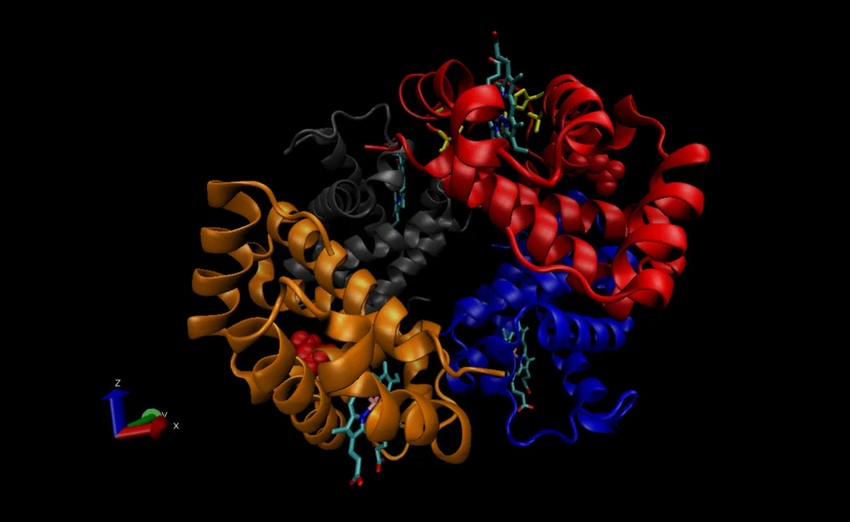

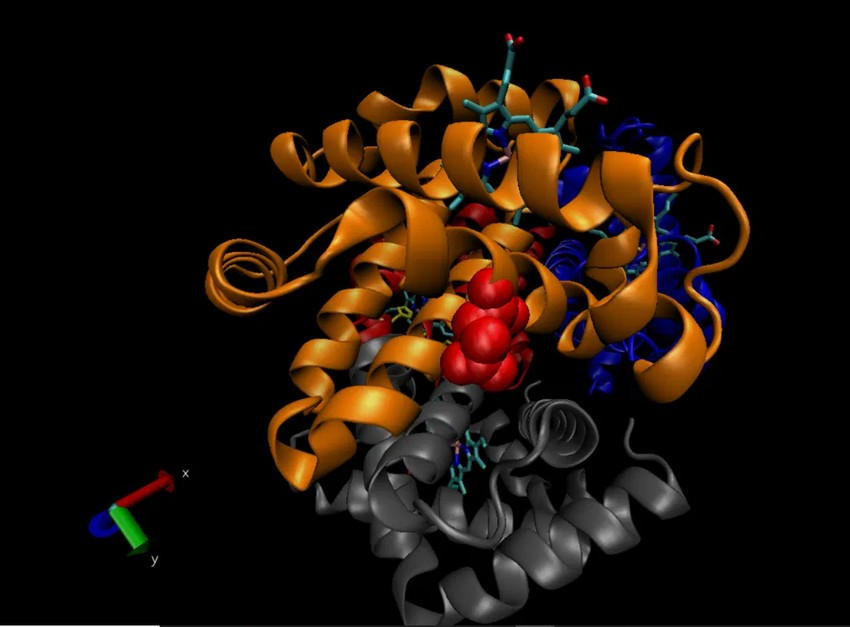

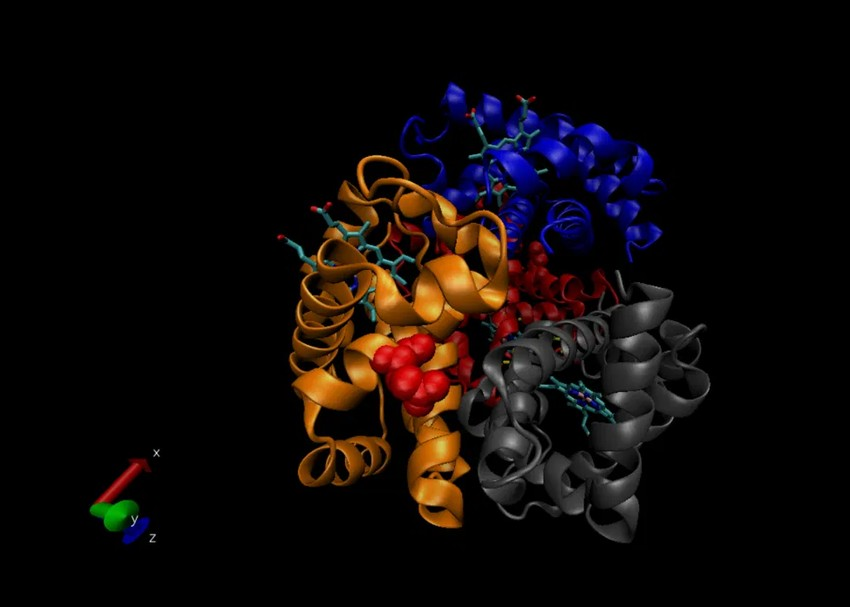
</center>

### 3.4.3 Visualizacion de los modelos de AlphaFold.

AlphaFold tiende a predecir la misma estructura global ante mutaciones puntuales, por la forma en que está entrenado; frecuentemente no modela el desplegamiento de las proteínas inestables, aunque ese efecto suele reflejarse en una caída de la confianza de la predicción. Usamos las predicciones de la forma silvestre y de la mutante E26K para estimar el impacto estructural de la sustitución.

- Estructura de B-Globina Silvestre:

> 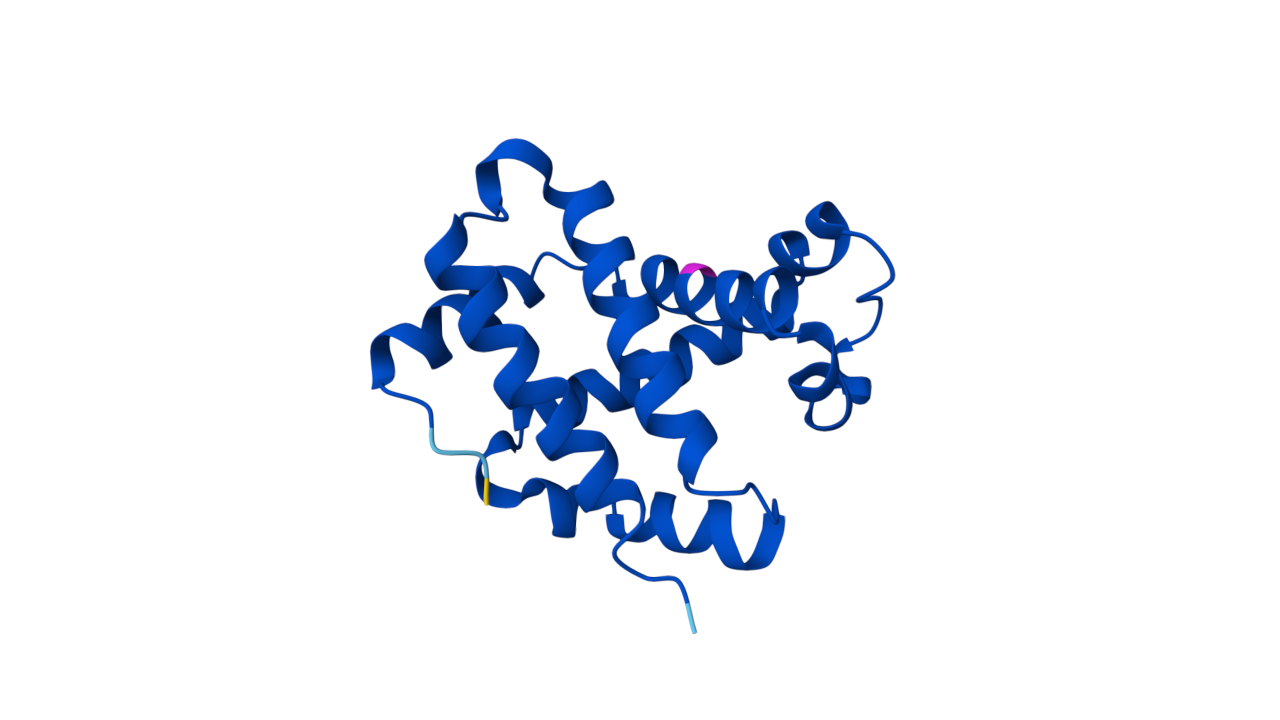

> En rosa se resalta el residuo que nos interesa estudiar.

- Estructura de B-Hemoglobina Mutada `(E26K)`:

> 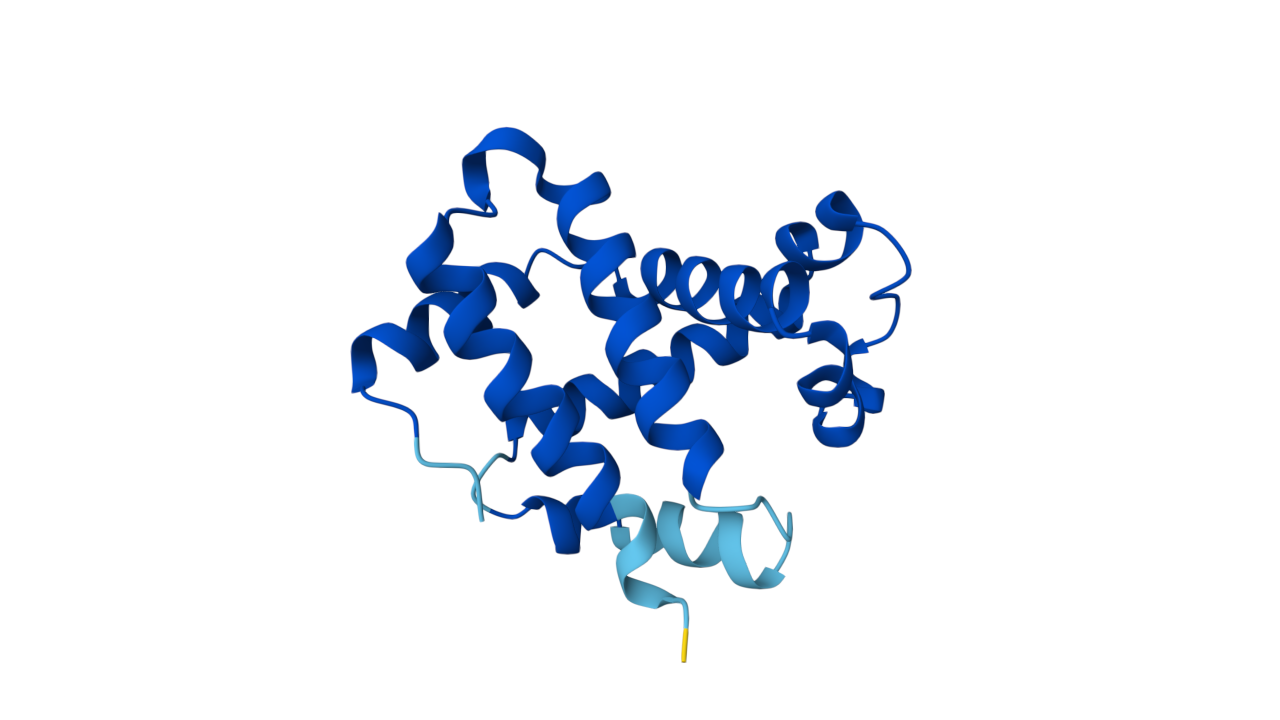


Para un primer acercamiento, esto es una respuesta positiva, el modelo original tiene una confianza muy alta. Algo esperable por tratarse de la hemoglobina humana. Sin embargo, sobre la mutacion el modelo predice casi con la misma confianza, al menos, en un entorno cercano a la misma.

Podemos observar que la disminucion incluso es baja, concluyendo en que la Lisyna como mutacion realmente es compatible al menos con la estructura. Por que, de hecho, no se denotan diferencias sustanciales en el resto de la misma.

En un alineamiento estructural entre ambos modelos, con coloreo por diferencia de RMSD, podemos ver en la siguiente imagen que no se presentan diferencias estructurales notorias entre ambas predicciones.

> 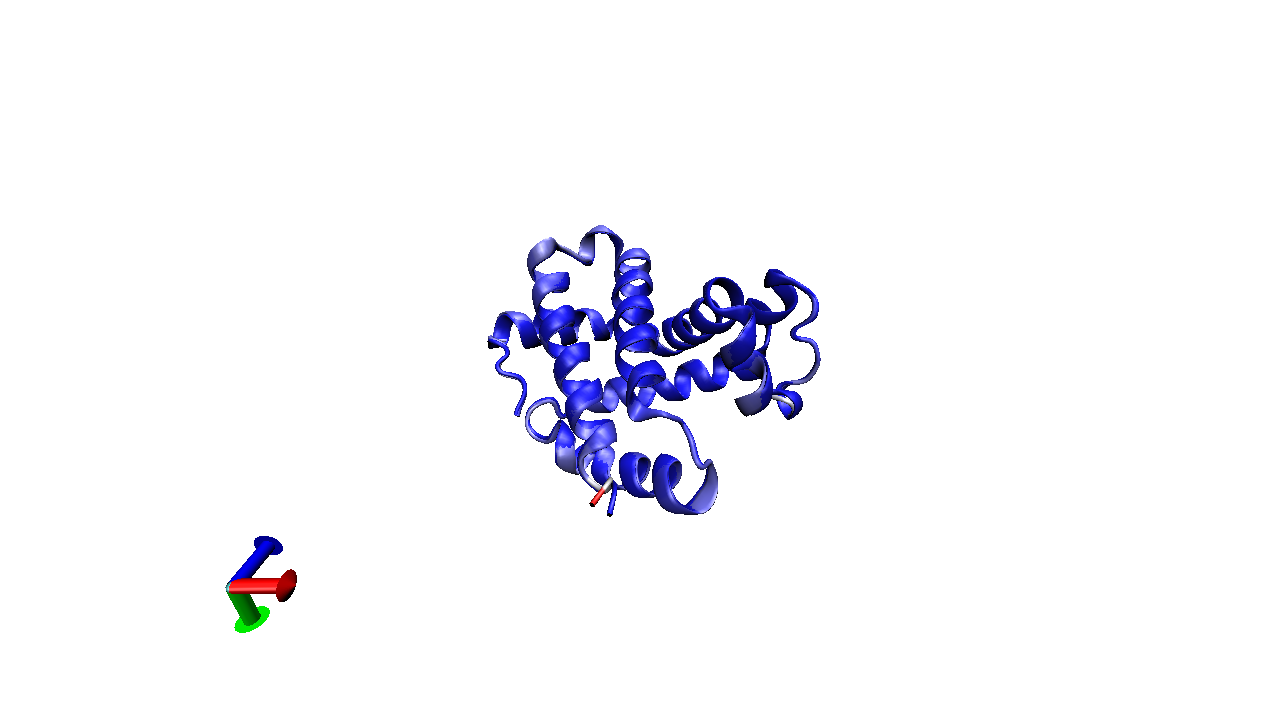

| RMSD | Qres |
|:------:|:-------:|
| 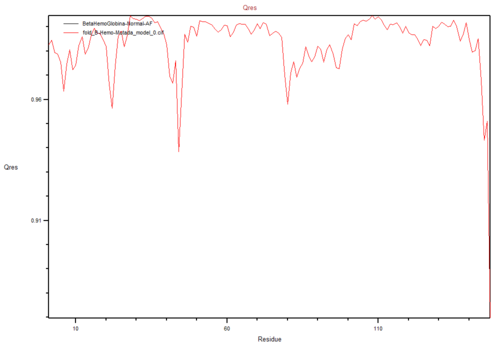 | ![](imagen2.png)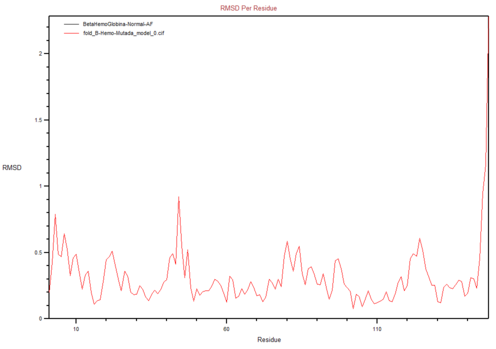 |

Salvo en las terminales, no se observa un cambio mayor a 1 Armstrong en el alnieamiento estructural.

### 3.4.4 - Visualizando el residuo en la Cristalografia

Estudiemos el modelo obtenido de la Cristalografia con el objetivo de obtener informacion sobre el entorno cercano de interacciones del aminoacido en la Beta-Hemoglobina Natural.

Empecemos usando los PDB's adjuntos en la bibliografia, correspondientes a hemoglobinas sin mutar:

> - 1HHO : Estructura de Hemoglobina Humana Oxigenada
> - 2HHB : Estructura de la Hemoglobina Humana Desoxigenada

Al comparar la posición de β26 entre la estructura desoxigenada (2HHB, estado T) y la oxigenada (1HHO, estado R) evaluamos cuánto se desplaza el residuo durante la transición alostérica. Alineamos ambas estructuras por su esqueleto y medimos el cambio de posición del residuo.

Alineamos ambas estructuras por su esqueleto y medimos el cambio de posición del residuo.

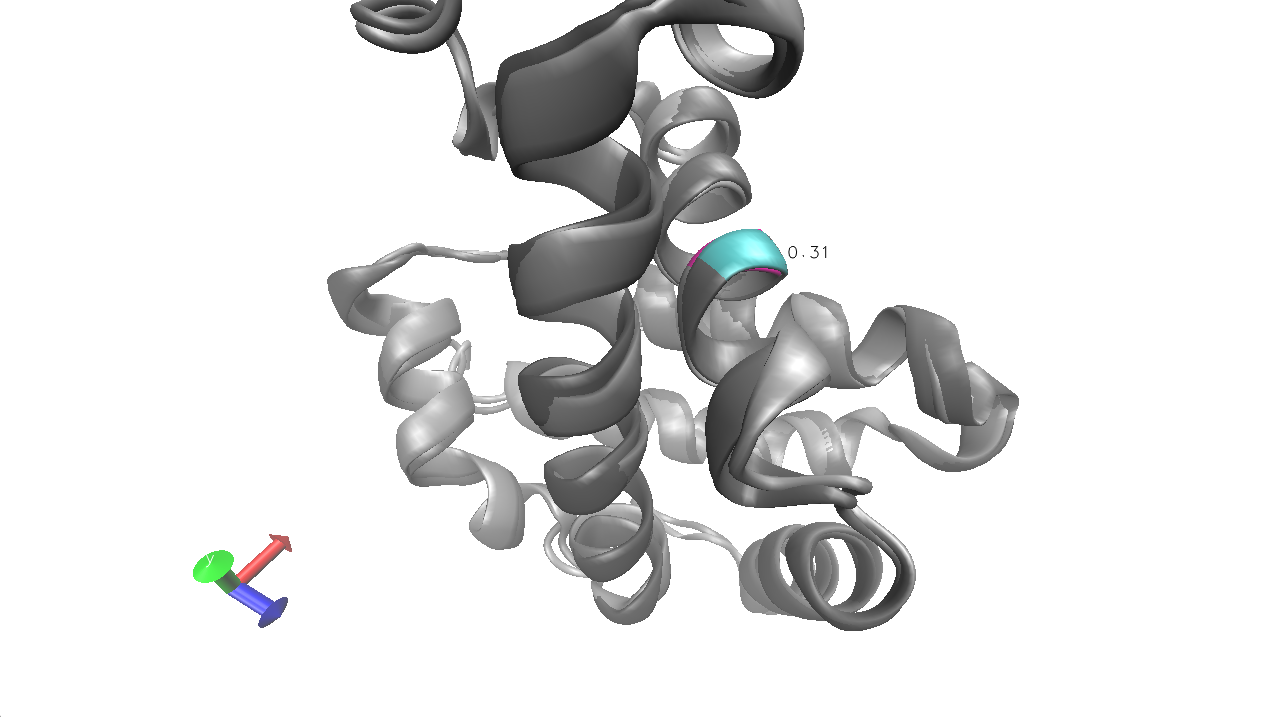

> La hemoglobina desoxigenada (proteina de color gris oscuro), tiene el aminoacido 26 (propio de la mutacion) pintado en Cyan.

> La hemoglobina oxigenada (proteina de color gris claro), tiene el aminoacido 26 (propio de la mutacion) pintado en Magenta.

En la imagen, la hemoglobina desoxigenada (gris oscuro) tiene el residuo 26 coloreado en cian y la oxigenada (gris claro) lo tiene en magenta. Tras el alineamiento de los esqueletos, la posición del residuo cambia apenas 0.31 Å entre ambos estados. El desplazamiento es muy bajo, lo que indica que β26 no participa del reordenamiento asociado a la transición T↔R.

Medimos también la distancia del residuo al hierro central del grupo hemo en cada uno de los dos estados.

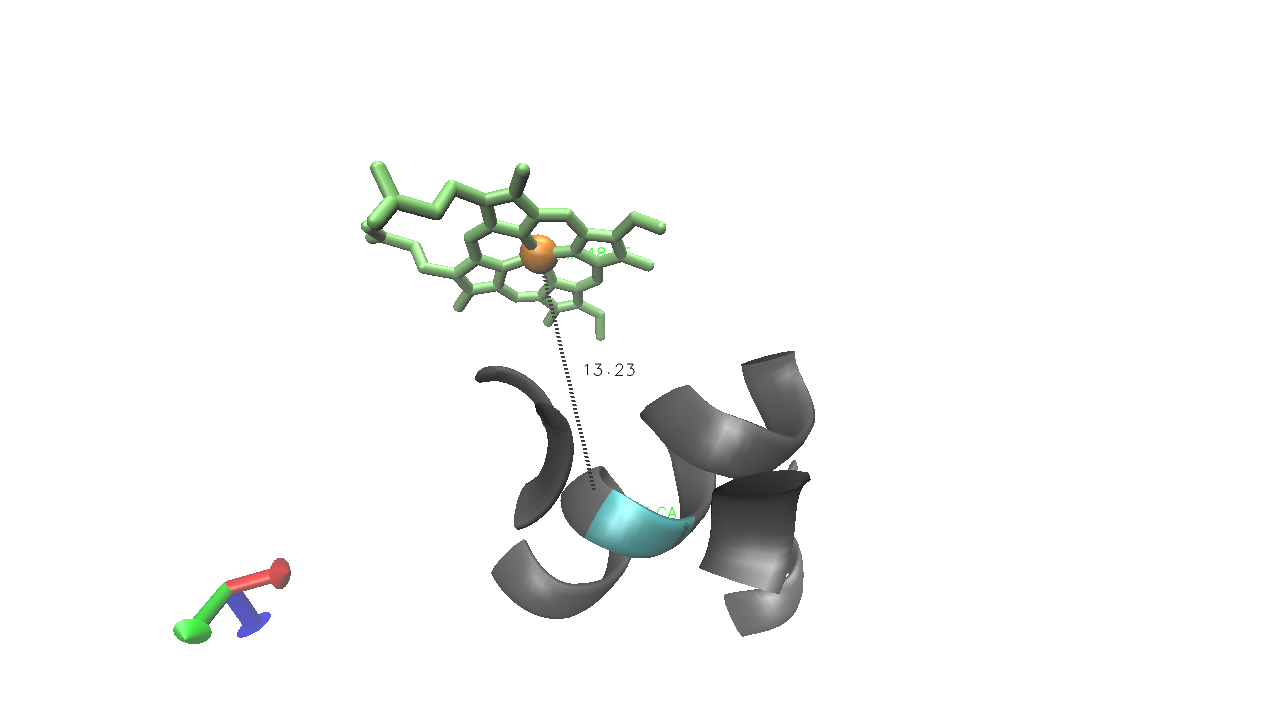



En un estado de desoxigenacion el residuo 26 queda a una distancia de $13.23 Å$ del hierro central del grupo hemo.

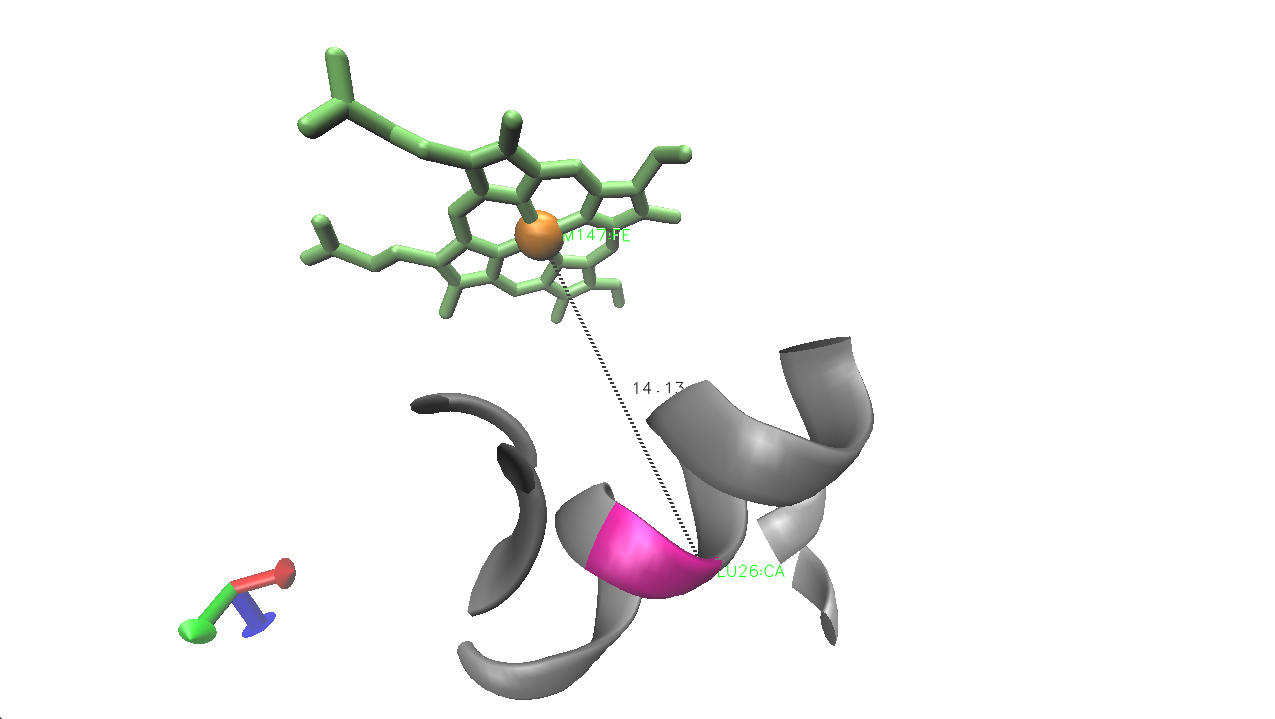

En un estado de oxigenacion el residuo 26 queda a una distancia de $14.13 Å$ del hierro central del grupo hemo.

En el estado desoxigenado el residuo 26 queda a unos 13.2 Å del hierro y en el oxigenado a unos 14.1 Å. Estas mediciones sobre VMD coinciden en orden de magnitud con la distancia mínima interatómica calculada sobre Biopython en la sección 3.4.1 (14.3 Å); la pequeña diferencia proviene del criterio de medición. En todos los casos el residuo queda muy por fuera del bolsillo del hemo, sin interacciones con el grupo prostético en ninguno de los dos estados. Físicamente, la posición no tiene un rol directo en la coordinación del hemo, de modo que el cambio de carga de la mutación no debería interferir con ese grupo.

Para tener en cuenta, la hemoglobina respira con un proceso que involucra "deslizar" sus cadenas alpha sobre sus beta. Sin embargo, este aminoacido en particular no tiene ningun tipo de enlace con la otra cadena, ni en estado desoxigenado, ni oxigenado.

Tampoco cambia abruptamente de posicion, veamos entonces si modifica los enlaces que tiene.

### 3.4.5 - Puentes de sal y de Hidrogeno

Usando la herramienta de VMD, extraimos dos archivos con los puentes de sal, en un estado desoxigenado y oxigenado, del PDB correspondiente.

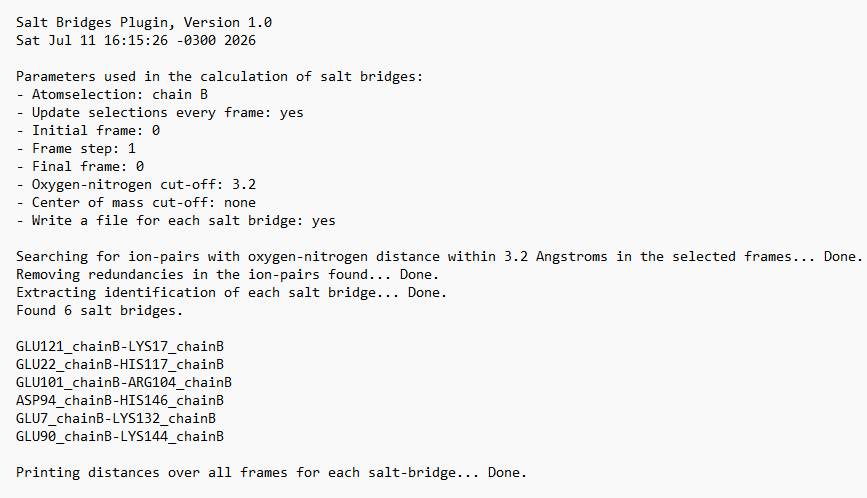

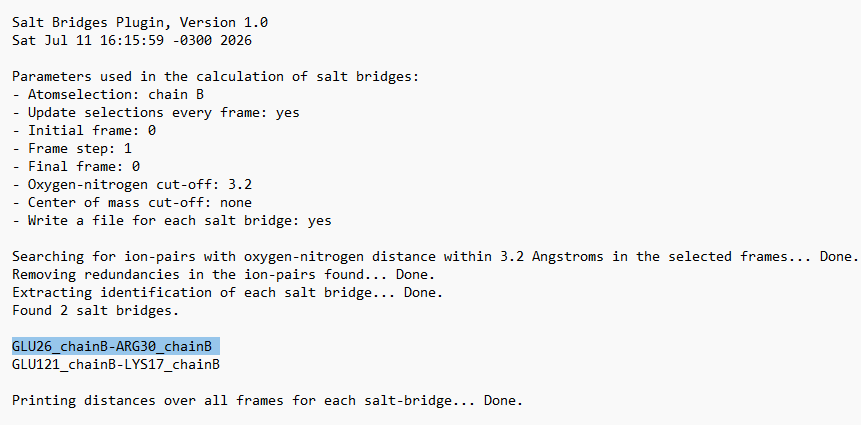

> Nota: Se ejecuto la herramienta de busqueda de enlaces de puentes de Hidrogeno y no se encontraron matches.

No se detectaron enlaces de hidrógeno en la posición 26 en ninguno de los dos estados. En el estado oxigenado (R), en cambio, β26 participa de un puente salino. Un puente salino combina una interacción iónica y un enlace de hidrógeno entre dos residuos de carga opuesta que se encuentran próximos. Dado que la mutación E→K invierte la carga del residuo, este puente es la única interacción local que la sustitución podría modificar; es, por lo tanto, el punto de partida natural para analizar el efecto del cambio de carga.

### 3.4.6 - Factor B en la cristalografia

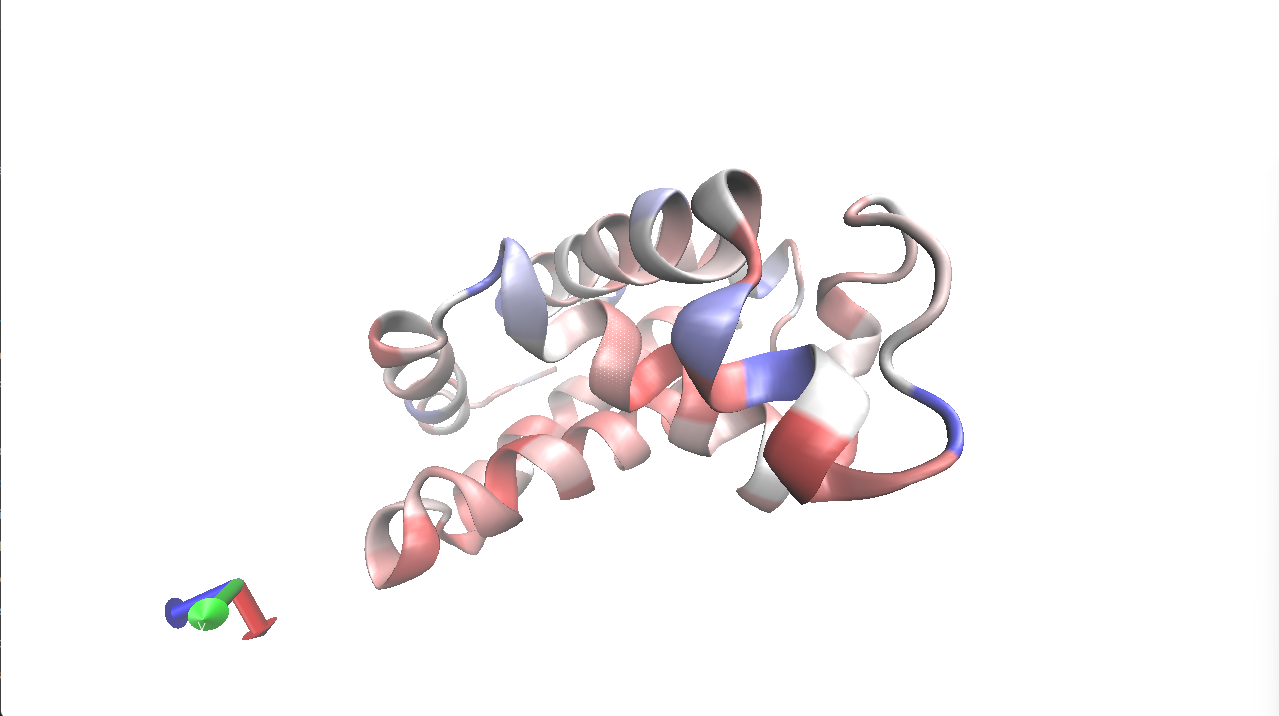

Coloreamos la estructura por factor B, el factor de temperatura que refleja la incertidumbre posicional de cada átomo en el cristal. El residuo 26, marcado con un patrón de puntos blancos para distinguirlo sin perder el coloreo por factor B, presenta un factor B bajo, es decir, una posición bien determinada y ordenada en la estructura. Esto confirma que la ubicación superficial que le asignamos es confiable y no un artefacto de una región desordenada del modelo. En conjunto, la certeza sobre su posición es alta, su desplazamiento entre estados es bajo y no registra interacciones con el proceso de oxigenación ni con el grupo hemo, con la única salvedad del puente de sal en el estado oxigenado.

### 3.4.7 - Accesibilidad al Solvente

Las mutaciones superficiales suelen tolerarse mejor porque el solvente que rodea a la proteína puede reorganizarse para acomodar el nuevo residuo. Un valor alto de accesibilidad al solvente (SASA) demuestra físicamente que el residuo está expuesto en la superficie, lo que justifica que la sustitución no desestabilice el empaquetamiento interno de la globina. Calculamos el SASA del residuo 26 en los dos estados conformacionales.

Analizamos la accesibilidad al solvente en un estado de desoxigenacion

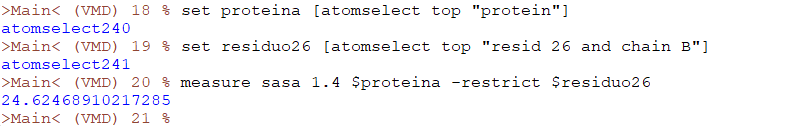

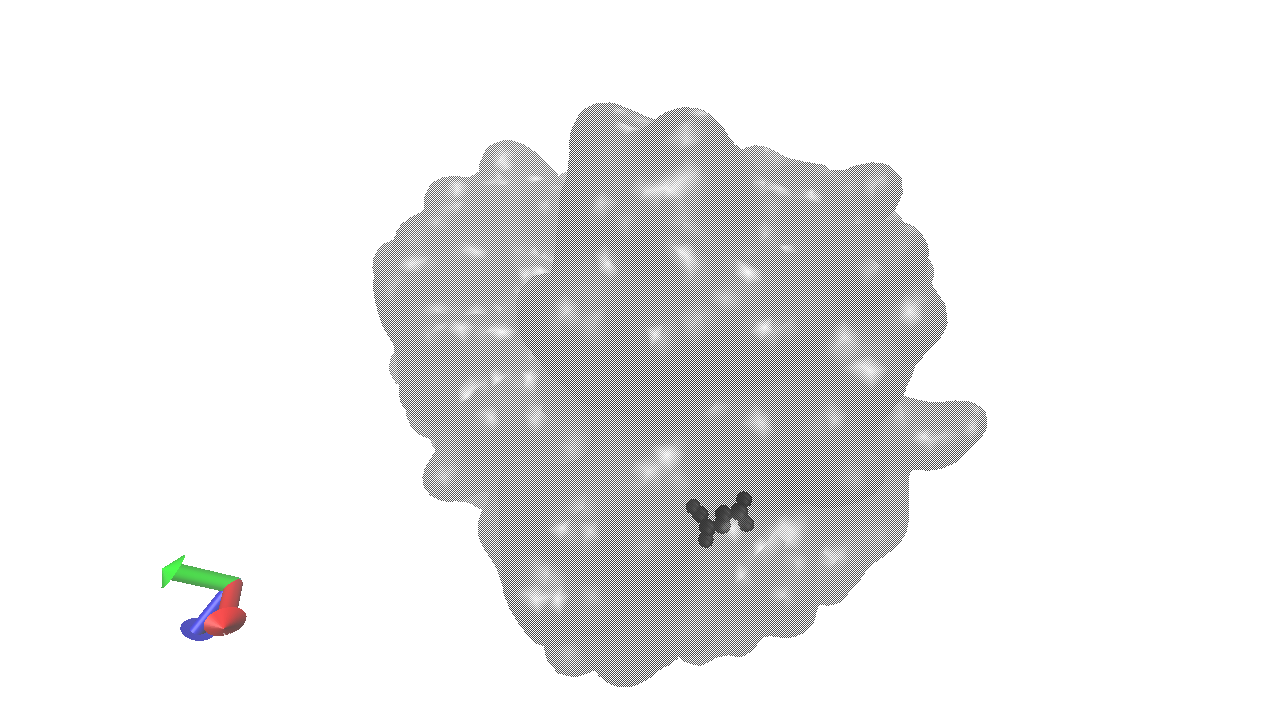

Analizamos la accesibilidad al solvente en un estado de oxigenacion:

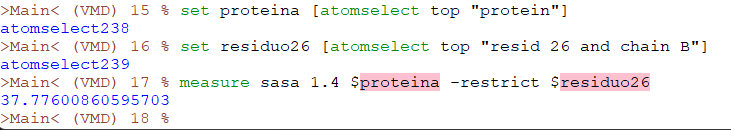

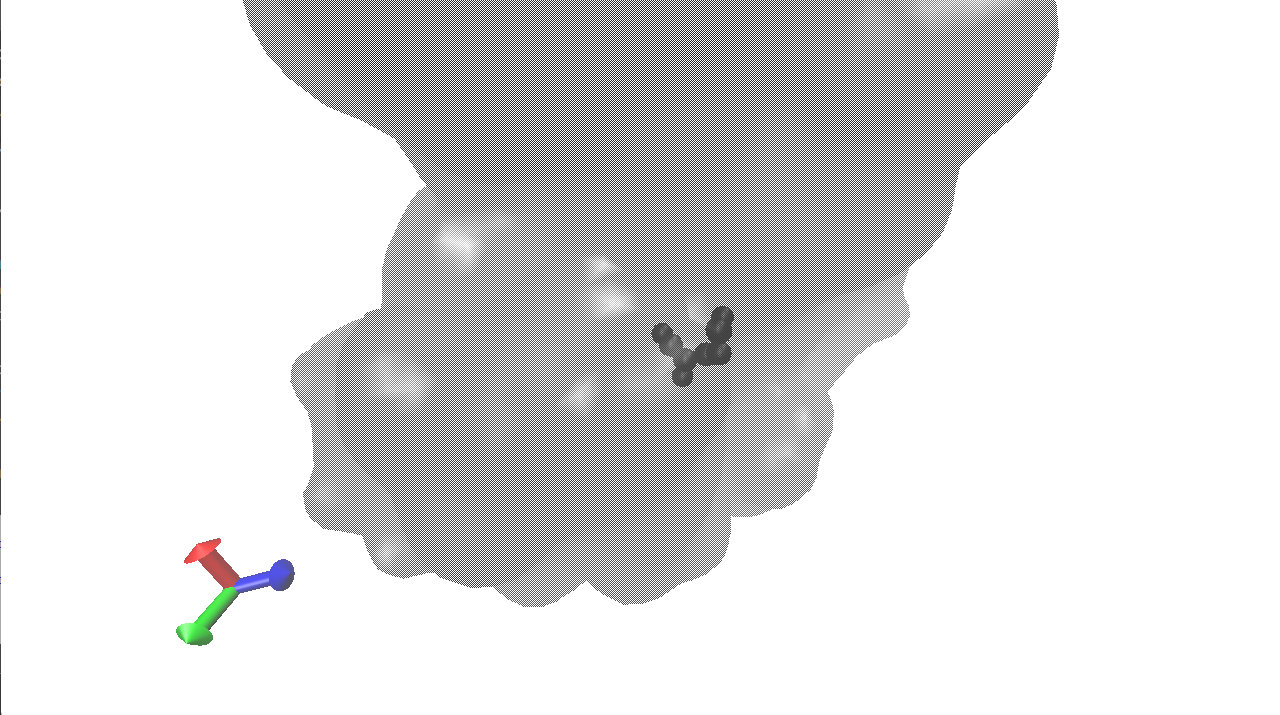

En ambos estados, oxigenado y desoxigenado, la exposición al solvente de β26 es alta, con un valor algo mayor en el estado oxigenado. Esto confirma, de forma independiente al cálculo de distancias, que el residuo se encuentra en la superficie de la proteína y expuesto al medio acuoso, en coincidencia con el resto del mapeo estructural.

## 3.5 - Comparación estructural con la mutante experimental (3DUT vs 2HHB)

Los análisis anteriores caracterizan la posición β26 y comparan la forma silvestre con un modelo predicho de la mutante. Disponemos, además, de la estructura cristalográfica experimental de la Hemoglobina E (3DUT), lo que permite la prueba más directa de la hipótesis: comparar la mutante experimental con la silvestre y medir cuánto cambia realmente la estructura. Realizamos la comparación en el mismo estado conformacional —ambas estructuras desoxigenadas, estado T (2HHB silvestre, 3DUT mutante)— para aislar el efecto de la mutación del reordenamiento alostérico T↔R.

Superponemos las cadenas β por sus carbonos α mediante el algoritmo de Kabsch (Superimposer de Bio.PDB) y calculamos tres RMSD: el global de la cadena β mutante frente a la silvestre, el local en la ventana de la hélice B que contiene β26 (residuos 20–32), y un valor de referencia interno —el RMSD entre las dos copias de la cadena β silvestre dentro del propio cristal 2HHB—, que cuantifica el ruido estructural intrínseco entre dos subunidades idénticas.

In [ ]:
# Comparacion estructural: HbE experimental (3DUT) vs silvestre (2HHB), ambas desoxi (estado T).
# Superposicion de Ca por Kabsch (Superimposer de Bio.PDB).

from Bio.PDB import PDBParser, Superimposer

!wget -q -O 2HHB.pdb https://files.rcsb.org/download/2HHB.pdb
!wget -q -O 3DUT.pdb https://files.rcsb.org/download/3DUT.pdb

AA3 = {'ALA':'A','ARG':'R','ASN':'N','ASP':'D','CYS':'C','GLN':'Q','GLU':'E',
       'GLY':'G','HIS':'H','ILE':'I','LEU':'L','LYS':'K','MET':'M','PHE':'F',
       'PRO':'P','SER':'S','THR':'T','TRP':'W','TYR':'Y','VAL':'V'}

p = PDBParser(QUIET=True)
wt  = p.get_structure("2HHB", "2HHB.pdb")[0]   # WT desoxi (T)
mut = p.get_structure("3DUT", "3DUT.pdb")[0]   # HbE desoxi (T)

def residuos_ca(chain):
    return [r for r in chain if r.id[0] == " " and "CA" in r and r.resname in AA3]

def info(model, nombre):
    print(nombre)
    d = {}
    for ch in model:
        n = len(residuos_ca(ch))
        if n > 0:
            print(f"   cadena {ch.id}: {n} CA"); d[ch.id] = n
    return d

def betas(d):
    m = max(d.values());  return [c for c, n in d.items() if n == m]

def ca(res):
    a = res["CA"];  return a.disordered_get_list()[0] if a.is_disordered() else a

def rmsd(rA, rB, sl=None):
    A = [ca(r) for r in rA]; B = [ca(r) for r in rB]
    if sl: A, B = A[sl], B[sl]
    n = min(len(A), len(B)); A, B = A[:n], B[:n]
    s = Superimposer(); s.set_atoms(B, A);  return s.rms, n

dW = info(wt,  "2HHB (WT desoxi, T)")
dM = info(mut, "3DUT (HbE desoxi, T)")
bW = betas(dW); bM = betas(dM)
print("\nCadenas beta ->  2HHB:", bW, " | 3DUT:", bM)

bW1 = residuos_ca(wt[bW[0]]); bM1 = residuos_ca(mut[bM[0]])
print("Residuo 26   ->  2HHB:", AA3[bW1[25].resname], " | 3DUT:", AA3[bM1[25].resname])

rg, n1 = rmsd(bW1, bM1)
rl, n2 = rmsd(bW1, bM1, sl=slice(19, 32))   # ventana local: residuos 20-32 (helice B)
print(f"\nRMSD Ca beta global (2HHB vs 3DUT): {rg:.3f} A  ({n1} res)")
print(f"RMSD Ca local, residuos 20-32     : {rl:.3f} A  ({n2} res)")
if len(bW) >= 2:
    bW2 = residuos_ca(wt[bW[1]])
    rb, n3 = rmsd(bW1, bW2)
    print(f"RMSD Ca beta1 vs beta2 de 2HHB    : {rb:.3f} A  ({n3} res)  [baseline WT-WT]")


2HHB (WT desoxi, T)
   cadena A: 141 CA
   cadena B: 146 CA
   cadena C: 141 CA
   cadena D: 146 CA
3DUT (HbE desoxi, T)
   cadena A: 141 CA
   cadena B: 146 CA
   cadena C: 141 CA
   cadena D: 146 CA

Cadenas beta ->  2HHB: ['B', 'D']  | 3DUT: ['B', 'D']
Residuo 26   ->  2HHB: E  | 3DUT: K

RMSD Ca beta global (2HHB vs 3DUT): 0.525 A  (146 res)
RMSD Ca local, residuos 20-32     : 0.591 A  (13 res)
RMSD Ca beta1 vs beta2 de 2HHB    : 0.251 A  (146 res)  [baseline WT-WT]


El chequeo de identidad confirma que la comparación es correcta: la posición 26 es un ácido glutámico en la estructura silvestre y una lisina en la mutante, de modo que 3DUT porta efectivamente la sustitución E26K en el residuo esperado. Ambas estructuras son tetrámeros α₂β₂ con la misma numeración.

El RMSD global de la cadena β entre la mutante y la silvestre es de 0.525 Å, y el RMSD local en el entorno de β26 (hélice B, residuos 20–32) es de 0.591 Å. Como referencia, el RMSD entre las dos cadenas β silvestres del propio cristal 2HHB —el ruido estructural entre dos subunidades idénticas— es de 0.251 Å. Los tres valores están muy por debajo de 1 Å. La diferencia entre la mutante y la silvestre es del orden del doble del ruido interno y se ubica en el rango habitual entre dos estructuras cristalográficas independientes de la misma proteína, y el entorno local de β26 no muestra una distorsión mayor que el promedio de la cadena. En otras palabras, la estructura experimental de la Hemoglobina E es prácticamente indistinguible de la silvestre: la mutación E26K, resuelta de forma experimental y no predicha, no produce un reordenamiento estructural significativo.

Este resultado es la evidencia más directa de la permisividad estructural de la posición. A diferencia del modelo de AlphaFold, que es una predicción, aquí se trata de la estructura cristalográfica real de la mutante, y confirma que el impacto de la sustitución sobre el plegamiento es mínimo, coherente con que su patología resida en la capa del ARN y no en la estructura de la proteína.

## 3.6 - Integración

El conjunto de las mediciones permite ordenar las variantes según su contexto estructural y contrastar el caso de la Hemoglobina E con las hemoglobinas inestables severas y con la Hemoglobina S.

| Posición | Variante | Contexto en 2HHB | Severidad | Mecanismo del daño |
|---|---|---|---|---|
| β26 | HbE (Glu→Lys) | Superficie — 14.3 Å al hemo, 13.6 Å a α1β2 | Leve/moderada (β⁺-tal) | Splicing críptico (capa de ARN) |
| β6 | HbS (Glu→Val) | Superficie — 27.8 Å al hemo | Severa | Polimerización intermolecular |
| β42 | Hb Hammersmith | Bolsillo del hemo — 6.7 Å al Fe | Severa (inestable) | Pérdida del hemo |
| β67 | Hb Bristol | Bolsillo del hemo — 4.1 Å al Fe | Severa (inestable) | Bolsillo del hemo alterado |
| β98 | Hb Köln | Enterrada/bolsillo — 5.8 Å al Fe | Severa (inestable) | Desestabilización del hemo |

Las dos posiciones superficiales del panel, β26 y β6, constituyen la clave del argumento: pertenecen a la misma clase estructural pero su daño se localiza en capas distintas. En la Hemoglobina S una posición superficial produce enfermedad severa a través de la polimerización intermolecular. En la Hemoglobina E, en cambio, la permisividad estructural de β26 —lejos del hemo, lejos de la interfaz alostérica, expuesta al solvente, sin cambio de posición apreciable en la transición T↔R y sin interacciones críticas más allá de un puente de sal— es compatible con una función esencialmente conservada, y su daño real se localiza en la capa del ARN, en el sitio críptico de splicing del exón 1 (Orkin et al., 1982). Esa tolerancia estructural es la condición que hace viable la variante y, por lo tanto, seleccionable bajo la presión de la malaria (Thein, 2013).

Conviene separar con claridad qué sostenemos con datos propios y qué se apoya en la bibliografía. La conservación de β26, su permisividad estructural, su distancia al hemo y a la interfaz, su exposición al solvente, su bajo desplazamiento entre estados y sus interacciones locales son resultados que obtuvimos y medimos directamente sobre las secuencias y las estructuras. El mecanismo de splicing críptico y la selección por malaria, en cambio, no son demostrables con estas herramientas y se apoyan en la literatura (Orkin et al., 1982; Thein, 2013).

# 4 - Conclusiones

El análisis estructural que se realizó a lo largo del informe demuestra que la mutación β26 Glu→Lys, característica de la Hemoglobina E, produce un impacto sorprendentemente pequeño sobre la arquitectura tridimensional de la proteína. A pesar de invertir completamente la carga del residuo, rompiendo el puente de sal que se forma en la hemoglobina silvestre, la lisina permanece localizada en una región superficial, con alta accesibilidad al solvente, alejada tanto del bolsillo hemo como de la interfaz alostérica. Por consiguiente, la mutación no altera la organización del núcleo hidrofóbico, ni modifica de manera apreciable las interacciones, permitiendo una compatibilidad con el plegamiento global. Esto es evidenciado por la similitud de los modelos de AlphaFold y, en particular, de las estructuras cristalográficas obtenidas experimentalmente.

Los resultados permiten inferir que la posición β26 constituye un entorno estructural permisivo. Su elevada exposición al solvente hace que el cambio de un aminoácido ácido por uno básico pueda ser amortiguado por el medio acuoso, evitando que la inversión de carga se traduzca en una reorganización de la estructura terciaria. La conservación evolutiva absoluta de tal residuo, sin embargo, no responde a las restricciones estructurales de la proteína madura, sino entonces a otro nivel funcional.

Explicando la aparente contradicción entre una posición que está demasiado conservada y una mutación que estructuralmente es casi neutra, pese al cambio de polaridad y acidez. Mientras que otras variantes inestables severas afectan a residuos enterrados en el núcleo de la proteína o directamente son involucrados en la estabilización del bolsillo hemo, localizados en entornos donde la accesibilidad al solvente es baja, o también mutaciones sobre residuos cuyos enlaces son mucho menos permisivos respecto de modificar las cargas. La posición analizada permanece alejada de elementos críticos y conserva prácticamente intacta la conformación de la hemoglobina. Del mismo modo que la comparación con la mutación responsable de la Hemoglobina S evidencia que dos sustituciones superficiales pueden originar patologías completamente distintas cuando actúan mediante mecanismos diferentes, en la HbS la alteración surge por la generación de una superficie hidrofóbica que favorece la polimerización, mientras que en la HbE no se observa un mecanismo estructural equivalente. Pero siendo las dos sustituciones superficiales.

En este sentido, la notable similitud estructural entre la Hemoglobina E y la variante Hb New York, que comparten la sustitución de un residuo cargado por una lisina en una región superficial, sin alterar significativamente el plegamiento de la proteína, refuerza la idea de que este tipo de posiciones toleran cambios electrostáticos locales siempre que permanezcan expuestas al solvente y alejadas del núcleo estructural. Esta convergencia entre variantes distintas constituye una evidencia adicional de la permisividad de este entorno de la cadena β.

En conjunto, la evidencia obtenida permite concluir que el elevado impacto clínico de la Hemoglobina E no puede atribuirse a la estructura terciaria de la proteína; por el contrario, todo apunta a que la hemoglobina madura conserva prácticamente intactas todas sus propiedades estructurales. Mientras que la alteración funcional se origina en el procesamiento del ARN mensajero mediante la creación de un sitio críptico de splicing. De esta forma, el presente trabajo aporta una explicación estructural al fenómeno descrito por Deng et al. (2025): una variante que alcanzó alta frecuencia poblacional puede hacerlo precisamente porque el cambio aminoacídico es estructuralmente tolerable, permitiendo que la selección natural actúe sobre un defecto cuyo origen reside fuera de la estructura tridimensional de la hemoglobina.

# 5 - Proyeccion a Futuro:

Enlistamos a continuacion las posibles mejoras a realizar para este estudio:

### 5.1 Cálculo de Mapas de Potencial Electrostático Superficial (APBS - Poisson-Boltzmann).

Si bien es una herramienta no vista a lo largo de la cursada, con el paso de Ácido Glutámico (carga negativa,  −1 ) a Lisina (carga positiva,  +1 ) se invierte drásticamente la polaridad de esa región celular. El software resuelve las ecuaciones electrostáticas para pintar la superficie de la proteína (Rojo = negativo, Azul = positivo). El objetivo es demostrar que la HbE genera un "parche básico/positivo" anómalo en una zona que originalmente interactuaba con el solvente mediante cargas negativas.

### 5.2 - Medición de Distancias Interatómicas y Red de Puentes de Hidrógeno (PyMOL / VMD).

El grupo Hemo se mantiene en su sitio gracias a un bolsillo hidrofóbico y a interacciones electrostáticas en sus extremos (los grupos propionato, cargados negativamente). El objetivo es verificar si la carga positiva de la Lisina ejerce una atracción o repulsión anómala sobre el Hemo que altere su "anclaje" natural.

### 5.3 - Explicabilidad de la fuerza de presion de la Malaria y la Talasemia

Consolidar la comprensión del mecanismo evolutivo subyacente a la alta prevalencia de la Hemoglobina E y explicar de manera mecanicista la presión selectiva ejercida por la Malaria. Sabiendo que la misma queda expuesta al entrar en contacto con el grupo Hemo. Siendo entonces un indicador de que las personas con este tipo de mutacion, que desarrollan Talasemia, fueron resaltadas por la presion de entorno debido a la Malaria, intentar explicar esto en base al impacto de la mutacion puede ser una buena idea.

# 6 - Bibliografia:

Zhang Q, Li J, …, Xu X, Deng L. Multi-centric origins and gene flow shape the diversity of β-thalassemia mutations in Southern East Asia. Nat Commun. 2025;16:10220.

Orkin SH, Kazazian HH, Antonarakis SE, et al. Abnormal RNA processing due to the exon mutation of βE-globin gene. Nature. 1982;300:768–769.

Sen U, Dasgupta J, Choudhury D, et al. Crystal structures of HbA2 and HbE and modeling of hemoglobin delta4: interpretation of the thermal stability and the antisickling effect of HbA2 and identification of the ferrocyanide binding site in Hb. Biochemistry. 2004;43:12477–12488.

Dasgupta J, Sen U, Choudhury D, et al. Crystallization and preliminary X-ray structural studies of hemoglobin A2 and hemoglobin E isolated from β-thalassemic patients. Biochem Biophys Res Commun. 2003;303:619–623.

Salvatore F, Brunello FG, Schuster CD, Martí MA. A structure and function-based complete mutational map of Human Hemoglobin using AI. bioRxiv. 2025.

Thein SL. The molecular basis of β-thalassemia. Cold Spring Harb Perspect Med. 2013;3(5):a011700.


[Beta-Hemoglobina secuencia uniprot](https://www.uniprot.org/uniprotkb/P68871/entry)

[Hemoglobina humana en estado desoxigenado](https://www.rcsb.org/structure/2HHB#entity-2)

[Hemoglobina humana en estado oxigenado](https://www.rcsb.org/structure/1HHO#entity-2)

[Estructura experimental de la Hemoglobina E (mutante E26K)](https://www.rcsb.org/structure/3DUT)